# Laboratório de Ciência de Dados
## Aula 4 — Métodos de ensemble: Random Forest, Gradient Boosting e comparação de desempenho

### Situação

Na aula anterior, a equipe da **VGAbank** comparou diferentes classificadores para detectar fraudes e percebeu que a escolha de um modelo não deve ser feita apenas pela acurácia.

Nesta aula, vamos aprofundar uma ideia que apareceu naquele experimento:

> **Em vez de confiar em um único modelo, podemos combinar vários modelos para produzir uma decisão melhor?**

Essa é a ideia central dos **métodos de ensemble**.

### O que você vai fazer

Você irá:

- utilizar uma **Árvore de Decisão** como modelo de referência;
- compreender a ideia de **ensemble**;
- treinar um **Random Forest**;
- treinar um **Gradient Boosting**;
- comparar os modelos usando diferentes métricas;
- investigar se modelos mais complexos realmente apresentam melhor desempenho.

Execute as células na ordem e responda às perguntas antes de continuar quando solicitado.


# 1. Preparando o ambiente

Utilizaremos `pandas`, `numpy`, `matplotlib` e componentes do `scikit-learn`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

RANDOM_STATE = 42


# 2. Construindo o problema

Continuaremos no contexto da VGAbank.

Para que todos trabalhem com exatamente o mesmo conjunto de dados, criaremos uma base sintética e reprodutível de transações bancárias.

Teremos:

- **20.000 transações**;
- **12 atributos numéricos**;
- classe `0`: transação legítima;
- classe `1`: fraude;
- aproximadamente **2% de fraudes**.

Esse forte desbalanceamento é proposital e mantém a continuidade com a aula anterior.


In [4]:
X_array, y_array = make_classification(
    n_samples=20000,
    n_features=12,
    n_informative=7,
    n_redundant=3,
    n_repeated=0,
    n_classes=2,
    weights=[0.98, 0.02],
    class_sep=1.15,
    flip_y=0.004,
    random_state=RANDOM_STATE
)

nomes_atributos = [f"atributo_{i}" for i in range(1, 13)]

X = pd.DataFrame(X_array, columns=nomes_atributos)
y = pd.Series(y_array, name="fraude")

dados = X.copy()
dados["fraude"] = y

dados.head()


,atributo_1,atributo_2,atributo_3,atributo_4,atributo_5,atributo_6,atributo_7,atributo_8,atributo_9,atributo_10,atributo_11,atributo_12,fraude
0,-1.805179,-0.488406,1.204571,-0.672760,-3.666641,1.452528,-0.804030,-0.059361,4.490772,0.134788,-0.518104,-1.601058,0
1,-0.759748,-3.381307,-2.276327,-0.016769,0.493353,3.430820,2.950646,-0.641782,1.540264,-3.186938,2.416366,1.546310,0
2,-0.360218,-3.098628,-0.717903,-0.168465,1.465508,-1.546313,3.401499,-1.190919,1.031952,-0.305026,-0.643007,-0.849139,0
3,-1.249886,0.915291,-2.329675,0.079980,0.552347,1.152416,2.313062,-3.781812,0.370777,-1.977611,4.313184,1.502669,0
4,3.210016,-4.034749,3.324866,-0.509413,-3.858068,-1.310608,0.482680,-3.043711,-0.012611,-1.462848,1.464346,1.186053,0


In [5]:
distribuicao = pd.DataFrame({
    "quantidade": y.value_counts().sort_index(),
    "percentual": y.value_counts(normalize=True).sort_index() * 100
})

distribuicao.index = ["legítima", "fraude"]
distribuicao.round(2)


,quantidade,percentual
legítima,19573,97.86
fraude,427,2.14


### Pergunta 1

Antes de treinar qualquer modelo:

**Por que a acurácia, sozinha, pode ser uma métrica inadequada neste problema?**

Anote sua resposta. Esse conceito foi trabalhado na aula anterior.


# 3. Separando treino e teste

Utilizaremos:

- **70% dos dados para treinamento**;
- **30% para teste**.

O parâmetro `stratify=y` preserva aproximadamente a proporção de fraudes nos dois conjuntos.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

print("\nFraudes no treino:", y_train.sum())
print("Fraudes no teste:", y_test.sum())


Treino: (14000, 12)
Teste: (6000, 12)

Fraudes no treino: 299
Fraudes no teste: 128


# 4. Modelo de referência: uma única Árvore de Decisão

Antes de construir um ensemble, precisamos de uma referência.

Uma **Árvore de Decisão** cria sucessivas divisões nos dados. De forma simplificada, ela procura perguntas do tipo:

> `atributo_4 <= determinado valor?`

Cada divisão tenta separar melhor as classes.

Árvores são fáceis de utilizar e conseguem representar relações não lineares. Entretanto, uma árvore muito ajustada aos dados de treinamento pode capturar particularidades ou ruídos da amostra e apresentar desempenho pior em novos dados.

Esse fenômeno é chamado de **overfitting**.


In [7]:
arvore = DecisionTreeClassifier(
    random_state=RANDOM_STATE,
    class_weight="balanced"
)

arvore.fit(X_train, y_train)

print("Acurácia no treino:", round(arvore.score(X_train, y_train), 4))
print("Acurácia no teste:", round(arvore.score(X_test, y_test), 4))


Acurácia no treino: 1.0
Acurácia no teste: 0.9815


### Pergunta 2

Compare a acurácia de treino e teste.

Se a árvore apresenta desempenho quase perfeito no treinamento, mas pior no teste, o que isso sugere?

Não é necessário concluir apenas pela acurácia, mas essa diferença já fornece uma pista importante.


# 5. O que é um ensemble?

Um **ensemble** combina as previsões de vários modelos.

A intuição é semelhante a consultar várias pessoas em vez de depender de uma única opinião.

Entretanto, os modelos não são simplesmente repetidos de qualquer maneira. Diferentes técnicas de ensemble definem **como os modelos são construídos e como suas previsões são combinadas**.

Nesta aula estudaremos duas estratégias:

| Método | Ideia central |
|---|---|
| **Random Forest** | várias árvores são treinadas com variações dos dados e dos atributos; suas previsões são combinadas |
| **Gradient Boosting** | árvores são construídas sequencialmente; cada nova árvore procura corrigir os erros do conjunto anterior |

Essas duas estratégias representam duas ideias importantes:

**Bagging → modelos construídos de forma mais independente**

**Boosting → modelos construídos sequencialmente**


# 6. Random Forest: uma floresta em vez de uma árvore

O **Random Forest** constrói várias árvores de decisão.

Para introduzir diversidade entre elas, o algoritmo utiliza aleatoriedade tanto nas observações utilizadas para construir as árvores quanto nos atributos considerados nas divisões.

Em classificação, as árvores contribuem para a decisão final do conjunto.

A ideia é que:

> erros particulares de uma árvore podem ser compensados pelas demais.

Vamos treinar uma floresta com **200 árvores**.


In [8]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

print("Random Forest treinado.")


Random Forest treinado.


### Uma árvore versus muitas árvores

Compare a acurácia no treino e no teste.


In [10]:
comparacao_inicial = pd.DataFrame({
    "modelo": ["Árvore de Decisão", "Random Forest"],
    "acuracia_treino": [
        arvore.score(X_train, y_train),
        random_forest.score(X_train, y_train)
    ],
    "acuracia_teste": [
        arvore.score(X_test, y_test),
        random_forest.score(X_test, y_test)
    ]
})

comparacao_inicial.round(4)


,modelo,acuracia_treino,acuracia_teste
0,Árvore de Decisão,1.0,0.9815
1,Random Forest,1.0,0.9888


### Pergunta 3

A Random Forest eliminou completamente o overfitting?

Provavelmente não.

O objetivo de um ensemble não é garantir que o modelo nunca se ajuste demais aos dados, mas frequentemente **melhorar sua capacidade de generalização** em relação a um modelo individual.


# 7. Gradient Boosting: aprender com os erros anteriores

O **Gradient Boosting** utiliza outra estratégia.

Em vez de construir muitas árvores relativamente independentes, ele cria modelos **sequencialmente**.

A ideia simplificada é:

1. um primeiro modelo faz previsões;
2. observamos onde o conjunto está errando;
3. um novo modelo é adicionado para reduzir esses erros;
4. o processo continua;
5. as contribuições dos vários modelos são combinadas.

Assim, cada nova etapa depende do conjunto construído anteriormente.

> Random Forest e Gradient Boosting utilizam árvores, mas a maneira como constroem o ensemble é diferente.


In [11]:
gradient_boosting = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=RANDOM_STATE
)

gradient_boosting.fit(X_train, y_train)

print("Gradient Boosting treinado.")


Gradient Boosting treinado.


## 7.1 O papel de `learning_rate`

No Gradient Boosting, o parâmetro `learning_rate` controla quanto cada nova árvore contribui para o conjunto.

Um valor menor faz cada etapa produzir uma contribuição menor.

Isso frequentemente exige um número maior de árvores (`n_estimators`).

Portanto, esses dois hiperparâmetros estão relacionados:

> `learning_rate` ↔ `n_estimators`

Não existe um valor universalmente melhor.


# 8. Comparando os três modelos

Agora temos:

1. Árvore de Decisão;
2. Random Forest;
3. Gradient Boosting.

Vamos avaliar todos exatamente no **mesmo conjunto de teste**.


In [12]:
modelos = {
    "Árvore de Decisão": arvore,
    "Random Forest": random_forest,
    "Gradient Boosting": gradient_boosting
}


Criaremos uma função para calcular várias métricas.

Utilizaremos:

- **acurácia**;
- **precisão**;
- **recall**;
- **F1-score**;
- **ROC-AUC**;
- **PR-AUC**.

Como nosso conjunto é fortemente desbalanceado, não devemos concentrar a análise apenas na acurácia.


In [13]:
def avaliar_modelo(nome, modelo, X_teste, y_teste):
    y_pred = modelo.predict(X_teste)
    y_prob = modelo.predict_proba(X_teste)[:, 1]

    return {
        "modelo": nome,
        "acuracia": accuracy_score(y_teste, y_pred),
        "precisao": precision_score(y_teste, y_pred, zero_division=0),
        "recall": recall_score(y_teste, y_pred, zero_division=0),
        "f1": f1_score(y_teste, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_teste, y_prob),
        "pr_auc": average_precision_score(y_teste, y_prob)
    }


resultados = []

for nome, modelo in modelos.items():
    resultados.append(
        avaliar_modelo(nome, modelo, X_test, y_test)
    )

tabela_resultados = pd.DataFrame(resultados)
tabela_resultados.round(4)


,modelo,acuracia,precisao,recall,f1,roc_auc,pr_auc
0,Árvore de Decisão,0.9815,0.5669,0.5625,0.5647,0.7766,0.3282
1,Random Forest,0.9888,0.9692,0.4922,0.6528,0.9471,0.8077
2,Gradient Boosting,0.9880,0.8889,0.5000,0.6400,0.9042,0.6779


# 9. Interpretando as métricas

Não procure imediatamente uma única coluna para declarar o vencedor.

Cada métrica responde a uma pergunta diferente.

**Precisão**

Entre as transações classificadas como fraude, qual proporção realmente era fraude?

**Recall**

Entre todas as fraudes existentes, qual proporção o modelo conseguiu detectar?

**F1-score**

Produz um equilíbrio entre precisão e recall.

**ROC-AUC**

Avalia a capacidade de ordenação/separação entre as classes considerando vários thresholds.

**PR-AUC**

Resume a relação entre precisão e recall ao variar o threshold e costuma ser especialmente informativa quando a classe positiva é rara.

> Em dados desbalanceados, comparar modelos exige olhar além da acurácia.


### Pergunta 4

Observe `tabela_resultados`.

Responda:

**a)** Qual modelo apresenta maior acurácia?

**b)** Qual apresenta maior recall?

**c)** Qual apresenta maior PR-AUC?

**d)** O mesmo modelo venceu em todas as métricas?

**e)** Isso altera a maneira como você definiria “melhor modelo”?


# 10. Visualizando ROC e Precision-Recall

Uma tabela resume os resultados, mas as curvas permitem observar o comportamento dos modelos ao longo de diferentes thresholds.


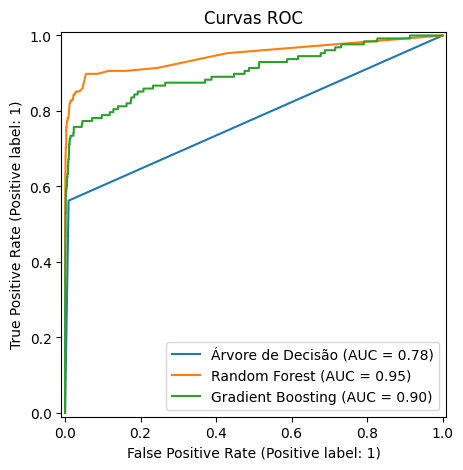

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))

for nome, modelo in modelos.items():
    RocCurveDisplay.from_estimator(
        modelo,
        X_test,
        y_test,
        name=nome,
        ax=ax
    )

plt.title("Curvas ROC")
plt.show()


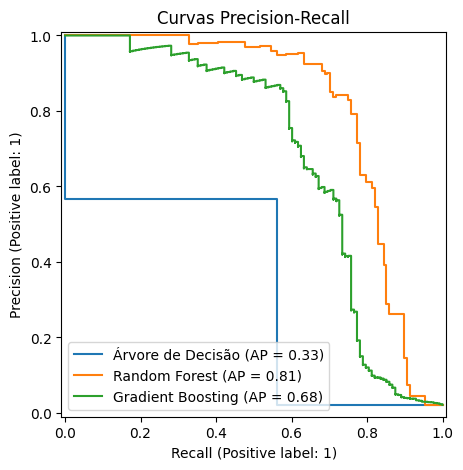

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))

for nome, modelo in modelos.items():
    PrecisionRecallDisplay.from_estimator(
        modelo,
        X_test,
        y_test,
        name=nome,
        ax=ax
    )

plt.title("Curvas Precision-Recall")
plt.show()


### Pergunta 5

Compare as duas visualizações.

Em um problema no qual apenas cerca de 2% das observações pertencem à classe positiva, qual das duas curvas ajuda a observar mais diretamente o compromisso entre:

> **detectar mais fraudes** × **produzir mais alertas incorretos**?

Relacione sua resposta aos conceitos de precisão e recall.


# 11. Matriz de confusão

As métricas agregadas são úteis, mas em um problema aplicado também é importante observar os erros concretos.

Vamos comparar as matrizes de confusão.


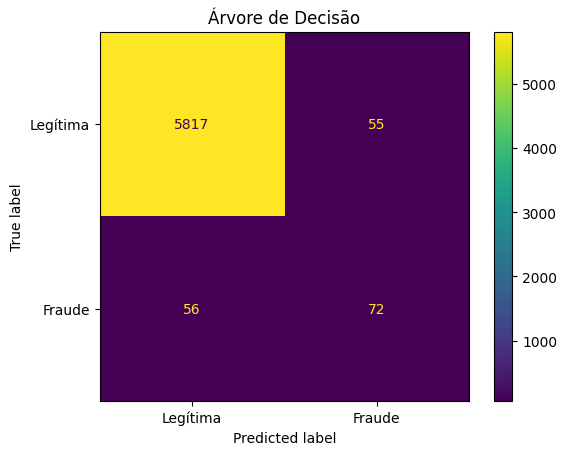

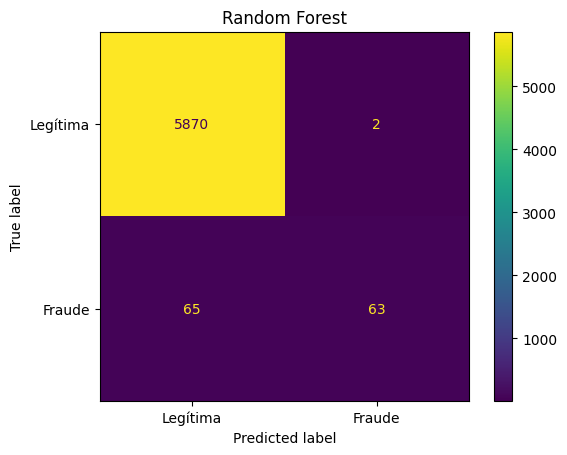

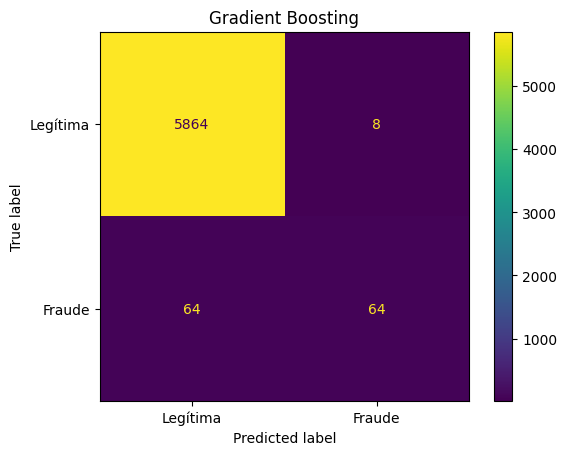

In [16]:
for nome, modelo in modelos.items():
    y_pred = modelo.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Legítima", "Fraude"]
    )

    plt.title(nome)
    plt.show()


### Pergunta 6

Para cada modelo, observe principalmente:

- **falsos positivos**: transações legítimas marcadas como fraude;
- **falsos negativos**: fraudes não detectadas.

Qual modelo apresenta o comportamento que você consideraria mais adequado para a VGAbank?

Sua resposta pode ser diferente daquela obtida olhando apenas para a acurácia.


# 12. O número de árvores importa?

Até agora utilizamos `n_estimators=200`.

Mas será que aumentar indefinidamente o número de árvores melhora necessariamente o desempenho?

Vamos testar diferentes tamanhos de Random Forest.

Para simplificar a comparação, utilizaremos a **PR-AUC**.


In [17]:
quantidades_arvores = [10, 25, 50, 100, 200, 400]

resultados_rf = []

for n in quantidades_arvores:
    modelo = RandomForestClassifier(
        n_estimators=n,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    modelo.fit(X_train, y_train)

    prob = modelo.predict_proba(X_test)[:, 1]

    resultados_rf.append({
        "n_estimators": n,
        "pr_auc": average_precision_score(y_test, prob)
    })

df_rf = pd.DataFrame(resultados_rf)
df_rf.round(4)


,n_estimators,pr_auc
0,10,0.7170
1,25,0.7666
2,50,0.7873
3,100,0.7983
4,200,0.8077
5,400,0.8112


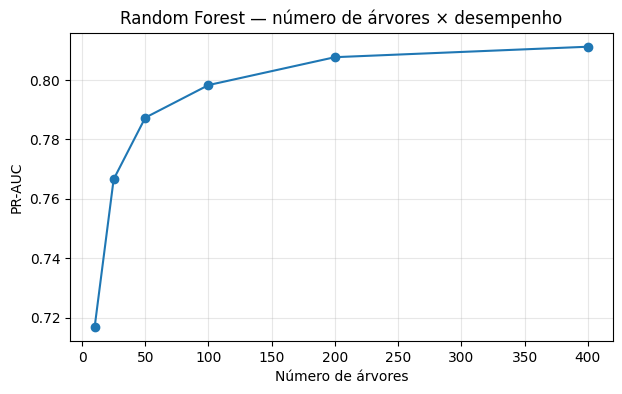

In [18]:
plt.figure(figsize=(7, 4))
plt.plot(
    df_rf["n_estimators"],
    df_rf["pr_auc"],
    marker="o"
)
plt.xlabel("Número de árvores")
plt.ylabel("PR-AUC")
plt.title("Random Forest — número de árvores × desempenho")
plt.grid(True, alpha=0.3)
plt.show()


### Pergunta 7

Observe o gráfico.

O ganho de desempenho cresce indefinidamente na mesma proporção conforme adicionamos árvores?

O que isso sugere sobre a ideia de simplesmente tornar um modelo cada vez maior?


# 13. Learning rate no Gradient Boosting

Agora faremos um pequeno experimento com o Gradient Boosting.

Manteremos o número de árvores fixo e modificaremos apenas o `learning_rate`.


In [19]:
learning_rates = [0.01, 0.03, 0.05, 0.10, 0.20]

resultados_gb = []

for lr in learning_rates:
    modelo = GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=lr,
        max_depth=3,
        random_state=RANDOM_STATE
    )

    modelo.fit(X_train, y_train)

    prob = modelo.predict_proba(X_test)[:, 1]

    resultados_gb.append({
        "learning_rate": lr,
        "pr_auc": average_precision_score(y_test, prob)
    })

df_gb = pd.DataFrame(resultados_gb)
df_gb.round(4)


,learning_rate,pr_auc
0,0.01,0.5584
1,0.03,0.6481
2,0.05,0.6779
3,0.10,0.6062
4,0.20,0.5710


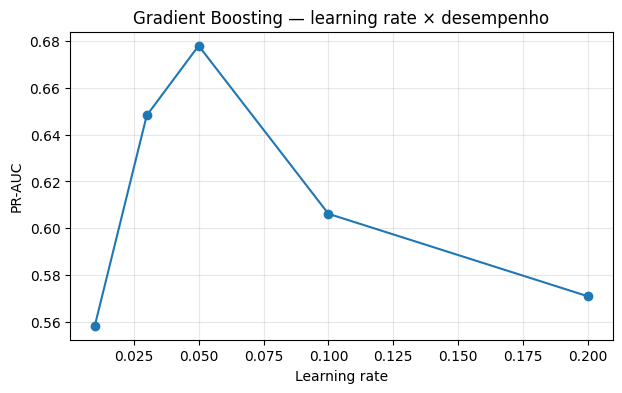

In [20]:
plt.figure(figsize=(7, 4))
plt.plot(
    df_gb["learning_rate"],
    df_gb["pr_auc"],
    marker="o"
)
plt.xlabel("Learning rate")
plt.ylabel("PR-AUC")
plt.title("Gradient Boosting — learning rate × desempenho")
plt.grid(True, alpha=0.3)
plt.show()


### Pergunta 8

O maior `learning_rate` produziu necessariamente o melhor resultado?

Esse experimento mostra uma característica importante de modelos de aprendizado de máquina:

> hiperparâmetros controlam o comportamento do algoritmo e precisam ser avaliados empiricamente.

Nesta aula estamos realizando apenas uma exploração didática. Em um projeto real, a seleção de hiperparâmetros deve ser feita de maneira mais cuidadosa, sem utilizar repetidamente o conjunto de teste para escolher a configuração.


# 14. Um cuidado metodológico importante

Nos experimentos anteriores, modificamos parâmetros e observamos o desempenho no conjunto de teste.

Isso foi feito para fins **didáticos**.

Em um projeto real, não devemos utilizar o conjunto de teste repetidamente para escolher:

- algoritmo;
- número de árvores;
- profundidade;
- learning rate;
- outros hiperparâmetros.

Caso façamos isso, o conjunto de teste deixa de representar uma avaliação realmente independente.

Uma abordagem adequada é utilizar:

> **treino → validação → teste**

ou técnicas como **validação cruzada**.

A seleção de hiperparâmetros será aprofundada em outro momento.


# 15. Random Forest versus Gradient Boosting

Agora podemos resumir as diferenças principais.

| Característica | Random Forest | Gradient Boosting |
|---|---|---|
| Estratégia | Bagging | Boosting |
| Construção das árvores | relativamente independentes | sequencial |
| Relação entre árvores | diversidade entre modelos | novas árvores corrigem o conjunto anterior |
| Paralelização | mais fácil | mais limitada pela natureza sequencial |
| Hiperparâmetro visto hoje | `n_estimators` | `n_estimators` e `learning_rate` |
| Objetivo geral | melhorar generalização pela combinação | melhorar progressivamente o conjunto |

Nenhum deles é universalmente superior.

A escolha depende:

- dos dados;
- da métrica relevante;
- dos hiperparâmetros;
- do custo computacional;
- do objetivo do problema.


# 16. Exercício — construa seu próprio ensemble

Sua tarefa agora é modificar os modelos.

### Parte A — Random Forest

Treine uma nova Random Forest utilizando:

```python
n_estimators=100
max_depth=8
class_weight="balanced"
```

Calcule:

- recall;
- F1;
- PR-AUC.

Compare com a Random Forest utilizada anteriormente.


In [21]:
# Complete aqui



### Parte B — Gradient Boosting

Treine um novo Gradient Boosting utilizando:

```python
n_estimators=100
learning_rate=0.10
max_depth=2
```

Calcule as mesmas métricas.

Compare com o Gradient Boosting anterior.


In [ ]:
# Complete aqui



# 17. Desafio final — recomendação à diretoria

Você deve enviar uma recomendação técnica curta à VGAbank.

Considere os resultados dos três modelos:

- Árvore de Decisão;
- Random Forest;
- Gradient Boosting.

Complete:

**Modelo recomendado:** ______________________________________

**Principal métrica utilizada para justificar a escolha:** ___________________

**Valor obtido:** ___________________________________________

**Por que você não utilizou apenas acurácia?**

________________________________________________________________

**Qual vantagem do ensemble foi observada em relação à árvore individual?**

________________________________________________________________

**Existe alguma razão para não afirmar que esse modelo será sempre o melhor?**

________________________________________________________________


# 18. Reflexão final

Responda brevemente:

**1. O que é um método de ensemble?**

**2. Qual é a diferença fundamental entre a estratégia da Random Forest e a do Gradient Boosting?**

**3. Por que uma única árvore pode apresentar overfitting?**

**4. Aumentar o número de árvores garante melhoria contínua do desempenho?**

**5. Por que PR-AUC é uma métrica relevante neste problema?**

**6. Por que não devemos escolher hiperparâmetros observando repetidamente o conjunto de teste?**


# 19. Conclusão

Nesta aula, partimos de uma única Árvore de Decisão e construímos dois ensembles.

O fluxo realizado foi:

**problema → árvore individual → ensemble → Random Forest → Gradient Boosting → métricas → comparação → decisão**

A principal ideia é:

> **Combinar modelos pode produzir melhor capacidade de generalização, mas a avaliação continua dependendo dos dados, da métrica e do objetivo do problema.**

Na prática, não existe um algoritmo que seja sempre o melhor. Ciência de Dados exige comparar alternativas de forma experimental e metodologicamente adequada.
